In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

from scipy.signal import welch
from specula.mmlib.filter_optimizers import optimize_iir_controller
from specula.mmlib.yaml_overrides import write_yaml_overrides

In [2]:
import matplotlib as mpl
from cycler import cycler

cmap = mpl.colormaps['hot'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 7)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'hot' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

In [3]:
seed = 10
np.random.seed(seed)
winds = np.round(np.random.uniform(0,1,10)*360,1).tolist()
overrides_yaml = 'temp_overrides'
ovdes = ("{"
        f"atmo.seed: {seed}, "
        f"wind_direction.constant: {winds}, "
        f"data_store.inputs.input_list: ['atmo_seed{seed:1.0f}_res-atmo_modes.out_modes'], "
        "}")
write_yaml_overrides(ovdes,temp_name=overrides_yaml)
os.system(f'specula atmo_open_loop.yml {overrides_yaml}.yml')

2026-10-28 10:13:06,636 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-10-28 10:13:11,253 [INFO]: [specula]: Default device is GPU number 0
2026-10-28 10:13:11,362 [INFO]: [specula.simul]: Reading parameters from atmo_open_loop.yml
2026-10-28 10:13:11,370 [INFO]: [specula.simul]: Reading additional parameters from temp_overrides.yml
2026-10-28 10:13:11,372 [INFO]: [specula.simul]: overrides: 
2026-10-28 10:13:11,372 [INFO]: [specula.simul]: self.trigger_order=['main', 'seeing', 'wind_speed', 'wind_direction', 'source_ngs', 'pupilstop', 'atmo', 'prop', 'atmo_modes', 'data_store']
2026-10-28 10:13:11,372 [INFO]: [specula.simul]: self.trigger_order_idx=[0, 0, 0, 0, 0, 0, 1, 2, 3, 4]
2026-10-28 10:13:11,373 [WARNING]: [specula.simul]: TODO: list of inputs is not handled in output replay
2026-10-28 10:13:11,373 [WARNING]: [specula.simul]: TODO: list of inputs is not handled in output replay
2026-10-28 10:13:11,553 [INFO]: [specula.simul]: Restoring: /raid1/mme

0

In [4]:
atmo_modes = fits.getdata(f'/raid1/mmenessini/results/VLT/atmo_seed{seed:1.0f}_res.fits')
atmo_modes.shape

(20000, 1835)

In [15]:
def get_correlation(vec,shift:int):
    vecm = vec - np.mean(vec)
    corr = np.sum(vecm[shift:]*vecm[:-shift])/np.sum(vec**2)#*len(vec)/(len(vec)-shift)
    return corr

idx = 100
R1 = get_correlation(atmo_modes[:,idx],shift=1)
R2 = get_correlation(atmo_modes[:,idx],shift=2)

AR1 = R1
alpha1 = R1*(1-R2)/(1-R1**2)
alpha2 = (R2-R1**2)/(1-R1**2)
AR2 = np.array([alpha1,alpha2])
print(R1,R2)
print(AR1,AR2)

0.9975807 0.996742
0.9975807 [0.67251966 0.32584938]


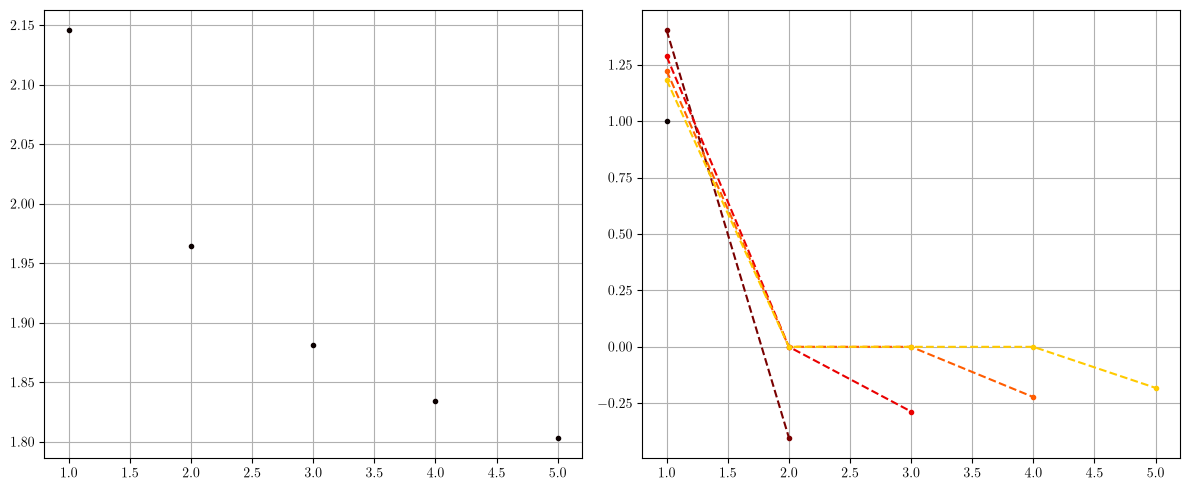

In [ ]:
# uk = a1 uk-1 + a2 uk-2 + nu
# U = A Ud

lags = np.arange(1,6)
idx = 0
err_rms = np.zeros(len(lags))
coeffs = np.ones([len(lags),len(lags)])*np.nan

for j,lag in enumerate(lags):
    modes = atmo_modes[:,idx]
    n = len(modes)
    u_meas = modes[lag:] 
    u_delayed = np.stack([
        modes[lag - k : n - k]
        for k in range(1, lag + 1)
    ])

    # Solve u_meas[t] ≈ A @ u_delayed[:, t]
    A = np.linalg.lstsq(u_delayed.T, u_meas, rcond=None)[0]

    u_est = A @ u_delayed
    err = u_est-u_meas

    coeffs[j,:len(A)] = A
    err_rms[j] = np.sqrt(np.mean(err**2))

    # plt.figure(figsize=(12,5))
    # plt.subplot(1,2,1)
    # plt.plot(modes)
    # plt.plot(np.arange(lag,n),u_est)
    # plt.grid()
    # plt.subplot(1,2,2)
    # plt.plot(np.arange(lag,n),err)
    # plt.xlim([0,1e+4])
    # plt.ylim([-3,3])
    # plt.grid()
    # plt.tight_layout()

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(lags,err_rms,'.')
plt.grid()

plt.subplot(1,2,2)
plt.plot(lags,coeffs.T,'--.')
plt.grid()
plt.tight_layout()

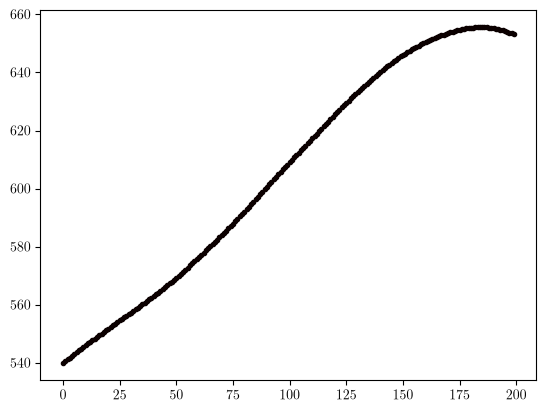

In [18]:
plt.figure()
plt.plot(atmo_modes[:200,0],'.')

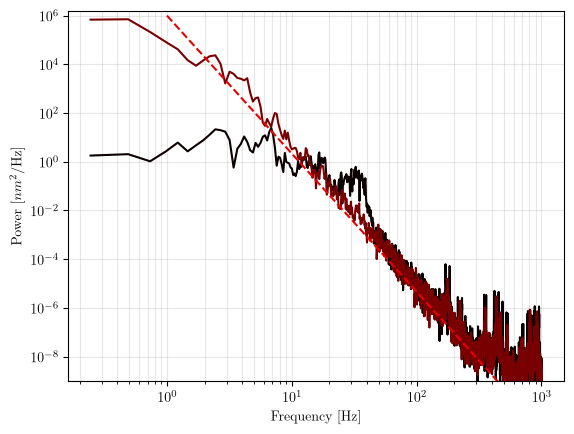

In [ ]:
f,psds = welch(atmo_modes, fs=2000, window='hann', nperseg=8192, axis=0, average='mean', scaling='density')

x = np.logspace(0,3,200)
y = 1e+6*x**(-17/3)

plt.figure()
plt.loglog(f[1:],psds[1:,200])
plt.loglog(f[1:],psds[1:,1])
plt.loglog(x,y,'--')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Power [$nm^2$/Hz]')
plt.ylim([1e-9,1.5e+6])
plt.grid(which='both',alpha=0.3)

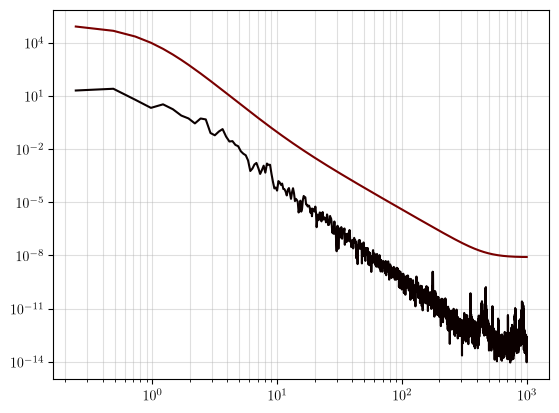

In [ ]:
psd = psds[1:,0]*(2*np.pi/750)**2 # nm^2 to rad^2
psd_noise = np.ones_like(f[1:])*(10*2*np.pi/750)**2
out = optimize_iir_controller(freq=f[1:],psd_turb=psd,psd_noise=psd_noise,fs=2000,delay=2,order=3,optical_gain=1.0)

rtf2 = abs(out['C_frequency_response'])**2

plt.figure()
plt.loglog(f[1:],psd)
plt.loglog(f[1:],rtf2)
plt.grid(which='both',alpha=0.4)